### **Ejercicio 3**

--> **Importamos las librerías**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
import warnings
warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True

--> **Leemos los datos**

In [2]:
# Carga de datos
co2 = pd.read_csv("C:\\Users\\Aturd\\OneDrive\\Escritorio\\Maestría\\semestre_2\\Forecasting\\tarea_2\\PHASE_2\\data\\Appendix 5 - co2-ppm-mauna-loa-19651980 1.csv")
temp = pd.read_csv("C:\\Users\\Aturd\\OneDrive\\Escritorio\\Maestría\\semestre_2\\Forecasting\\tarea_2\\PHASE_2\\data\\Appendix 6 - mean-monthly-temperature-1907-19.csv")

print("CO2 columnas:", co2.columns.tolist())
print("Temp columnas:", temp.columns.tolist())
print(co2.head())
print(temp.head())

CO2 columnas: ['Month', 'CO2 (ppm) mauna loa, 1965-1980']
Temp columnas: ['Month', 'Mean monthly temperature, 1907 ? 1972']
     Month CO2 (ppm) mauna loa, 1965-1980
0  1965-01                         319.32
1  1965-02                         320.36
2  1965-03                         320.82
3  1965-04                         322.06
4  1965-05                         322.17
     Month Mean monthly temperature, 1907 ? 1972
0  1907-01                                  33.3
1  1907-02                                  46.0
2  1907-03                                  43.0
3  1907-04                                  55.0
4  1907-05                                  51.8


In [3]:
co2.info()

<class 'pandas.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Data columns (total 2 columns):
 #   Column                          Non-Null Count  Dtype
---  ------                          --------------  -----
 0   Month                           193 non-null    str  
 1   CO2 (ppm) mauna loa, 1965-1980  193 non-null    str  
dtypes: str(2)
memory usage: 3.1 KB


In [4]:
temp.info()

<class 'pandas.DataFrame'>
RangeIndex: 793 entries, 0 to 792
Data columns (total 2 columns):
 #   Column                                 Non-Null Count  Dtype
---  ------                                 --------------  -----
 0   Month                                  793 non-null    str  
 1   Mean monthly temperature, 1907 ? 1972  793 non-null    str  
dtypes: str(2)
memory usage: 12.5 KB


--> **Limpieza y estruccturación de los datasets**

In [5]:
def prepare_series(df, value_col_index=1, name=""):
    df = df.copy()
    
    # seleccionamos dinámicamente la primera columna (0) y la columna de valor indicada
    # Esto evita errores si el DataFrame original tiene más de 2 columnas
    df = df.iloc[:, [0, value_col_index]]
    df.columns = ["Month", "Value"]          
    #  errors="coerce" convierte el texto "CO2 (ppm)..." en NaT (vacío)
    df["Month"] = pd.to_datetime(df["Month"], errors="coerce")
    # Convertimos los valores a números (también limpiando textos residuales)
    df["Value"] = pd.to_numeric(df["Value"], errors="coerce")
    # eliminamos las filas que tenían textos erróneos (ahora convertidas en NaN/NaT)
    df = df.dropna()
    # Ordenamos por el índice temporal
    df = df.set_index("Month").sort_index()
    
    print(f"--- {name} ---")
    print(f"Rango: {df.index.min().date()} → {df.index.max().date()}")
    print(f"N obs: {len(df)}")
    print(f"Frecuencia inferida: {pd.infer_freq(df.index)}")
    print(f"Estadísticas: min={df['Value'].min():.2f}, "
          f"max={df['Value'].max():.2f}, mean={df['Value'].mean():.2f}\n")
    return df


co2_df = prepare_series(co2, value_col_index=1, name="CO2 Mauna Loa")
temp_df = prepare_series(temp, value_col_index=1, name="Temperatura media mensual")


--- CO2 Mauna Loa ---
Rango: 1965-01-01 → 1980-12-01
N obs: 192
Frecuencia inferida: MS
Estadísticas: min=317.25, max=341.19, mean=328.46

--- Temperatura media mensual ---
Rango: 1907-01-01 → 1972-12-01
N obs: 792
Frecuencia inferida: MS
Estadísticas: min=11.20, max=82.40, mean=53.55



--> al hacer set_index("Month") con fechas, statsmodels reconoce la frecuencia automáticamente y las funciones de ACF/PACF y seasonal_decompose funcionan mejor.

In [6]:
# Extraemos las series como pd.Series con índice temporal
co2_ts = co2_df["Value"]
temp_ts = temp_df["Value"]

Acá el objetivo en este último código es es **simplificar la estructura de datos al pasar de un DataFrame (que es una tabla bidimensional con columnas) a una Series (que es un vector unidimensional con un índice temporal).**

--> **Visualización inicial**

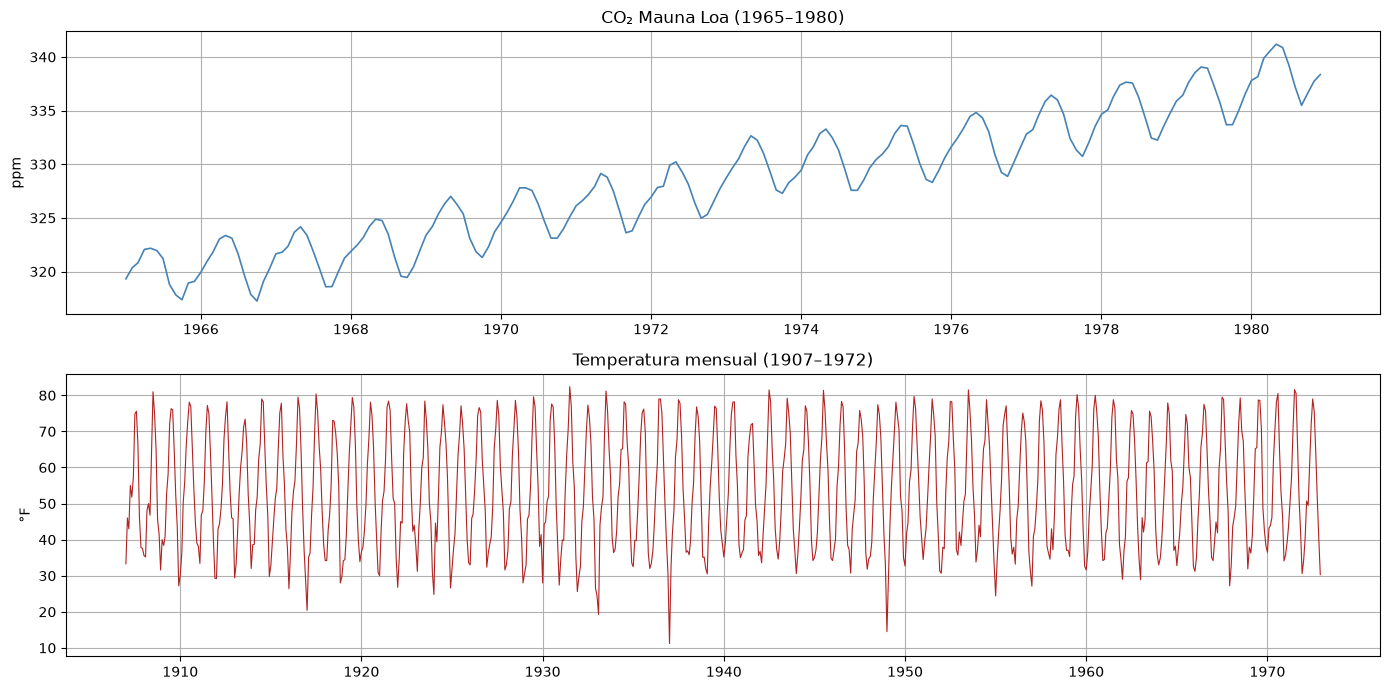

¡Figura guardada exitosamente en: C:\Users\Aturd\OneDrive\Escritorio\Maestría\semestre_2\Forecasting\tarea_2\PHASE_2\outputs\Visualización inicial de Co2 y Temperatura.png


In [7]:
import os
from pathlib import Path


# 1. Definir la ruta a la carpeta 'outputs' saliendo de la carpeta actual
# Path.cwd() obtiene la carpeta del notebook; .parent sube un nivel.
ruta_outputs = Path.cwd().parent / "outputs"

# 2. Crear la carpeta si por alguna razón aún no existe
ruta_outputs.mkdir(parents=True, exist_ok=True)

# 3. Definir el nombre del archivo final
archivo_guardado = ruta_outputs / "Visualización inicial de Co2 y Temperatura.png"


fig, axes = plt.subplots(2, 1, figsize=(14, 7))

axes[0].plot(co2_ts, color="steelblue", lw=1.2)
axes[0].set_title("CO₂ Mauna Loa (1965–1980)")
axes[0].set_ylabel("ppm")

axes[1].plot(temp_ts, color="firebrick", lw=0.8)
axes[1].set_title("Temperatura mensual (1907–1972)")
axes[1].set_ylabel("°F")

plt.tight_layout()


# 4. guardar la figura debe ir antes de plt.show()
# Usamos str() para que matplotlib entienda la ruta de pathlib correctamente
plt.savefig(str(archivo_guardado), dpi=300, bbox_inches="tight")

# 5. Mostrar y limpiar el lienzo
plt.show()
plt.close(fig)

print(f"¡Figura guardada exitosamente en: {archivo_guardado.resolve()}")


- CO₂:

Tendencia creciente clara de ~319 a ~338 ppm.

Estacionalidad anual muy marcada, se conoce como serrucho de periodo 12: sube en primavera, baja en otoño.

La amplitud estacional es constante --> estacionalidad aditiva o puede ser multiplicativa muy leve.



- Temperatura:

Estacionalidad anual muy fuerte, ciclo 12.

Sin tendencia clara a lo largo de 66 años, aunque puede haber una tendencia muy leve.

Amplitud estacional constante --> estacionalidad aditiva.

La serie parece estacionaria en media

--> **Test de estacionariedad (ADF + KPSS)**

In [8]:
def test_stationarity(series, name):
    adf_stat, adf_p, _, _, _, _ = adfuller(series, autolag="AIC")
    kpss_stat, kpss_p, _, _ = kpss(series, regression="c", nlags="auto")
    print(f"--- {name} ---")
    print(f"ADF  stat={adf_stat:8.4f}  p={adf_p:.4f}  → "
          f"{'estacionaria' if adf_p < 0.05 else 'NO estacionaria'}")
    print(f"KPSS stat={kpss_stat:8.4f}  p={kpss_p:.4f}  → "
          f"{'NO estacionaria' if kpss_p < 0.05 else 'estacionaria'}")
    return adf_p, kpss_p

adf_co2, kpss_co2 = test_stationarity(co2_ts, "CO2 original")
print()
adf_temp, kpss_temp = test_stationarity(temp_ts, "Temp original")

--- CO2 original ---
ADF  stat=  1.2697  p=0.9964  → NO estacionaria
KPSS stat=  1.9853  p=0.0100  → NO estacionaria

--- Temp original ---
ADF  stat= -6.4815  p=0.0000  → estacionaria
KPSS stat=  0.0179  p=0.1000  → estacionaria


**ADF (Augmented Dickey-Fuller Test)**

Objetivo: Detectar si la serie tiene una raíz unitaria (lo que genera una tendencia estocástica o "paseo aleatorio").

Hipótesis:$H_0$ (Hipótesis Nula): La serie NO es estacionaria (tiene raíz unitaria).

$H_1$ (Hipótesis Alternativa): La serie es estacionaria.

Criterio del p-valor: Si el p-valor es menor a $0.05$, rechazas la hipótesis nula $\rightarrow$ Estacionaria. Si es mayor, NO es estacionaria.


**KPSS (Kwiatkowski-Phillips-Schmidt-Shin Test)**

Objetivo: Probar la estacionariedad alrededor de un nivel o una tendencia determinista. Hipótesis (¡Funciona al revés que ADF!)

$H_0$ (Hipótesis Nula): La serie ES estacionaria.

$H_1$ (Hipótesis Alternativa): La serie NO es estacionaria.

Criterio del p-valor: Si el p-valor es menor a $0.05$, rechazas $H_0$ $\rightarrow$ NO es estacionaria.


--> Cuando KPSS dice que es estacionaria pero ADF dice que no, la serie suele ser estacionaria en torno a una tendencia (Trend-Stationary). La serie no tiene una raíz unitaria (por eso pasa KPSS), pero existe una tendencia determinista ascendente o descendente que hace que ADF falle.

--> conclusión del test de estacionalidad

para Co2
ADF y KPSS nos dicen que no es estacionaria
Coherentes: hay tendencia clara.


Temperatura:
ADF y KPSS no es dicen que es estacionaria.
Coherentes: no hay tendencia, solo ciclos.

-->**Descomposición estacional**

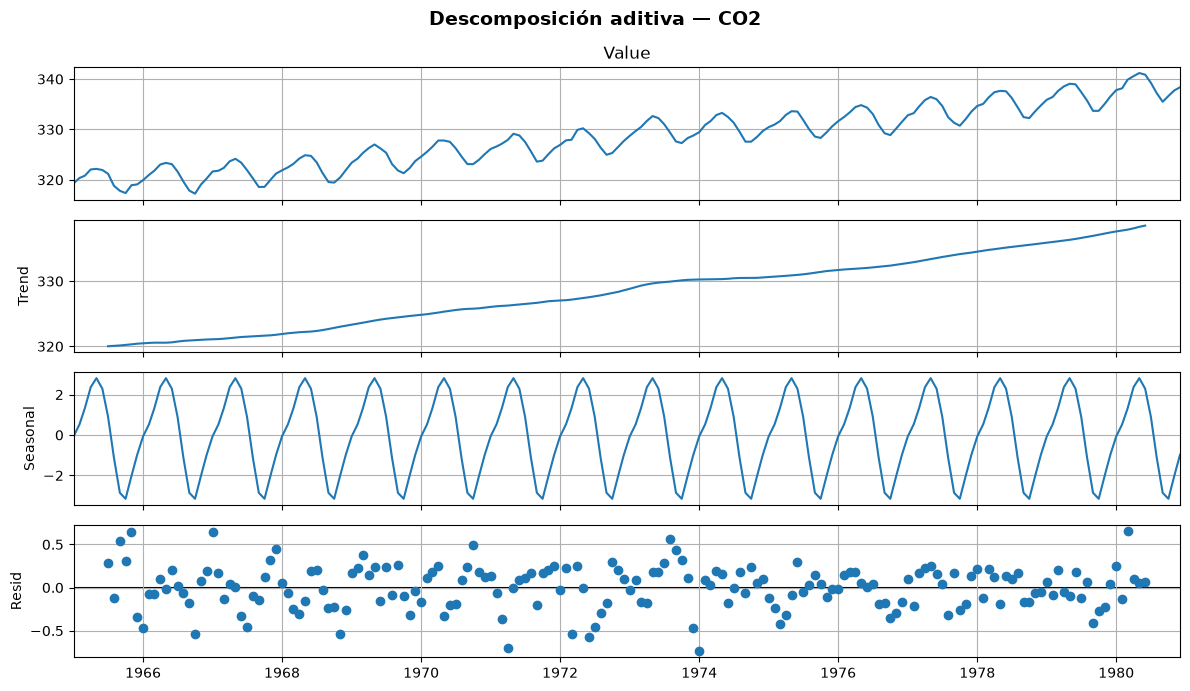

Fuerza tendencia:      0.998
Fuerza estacionalidad: 0.984


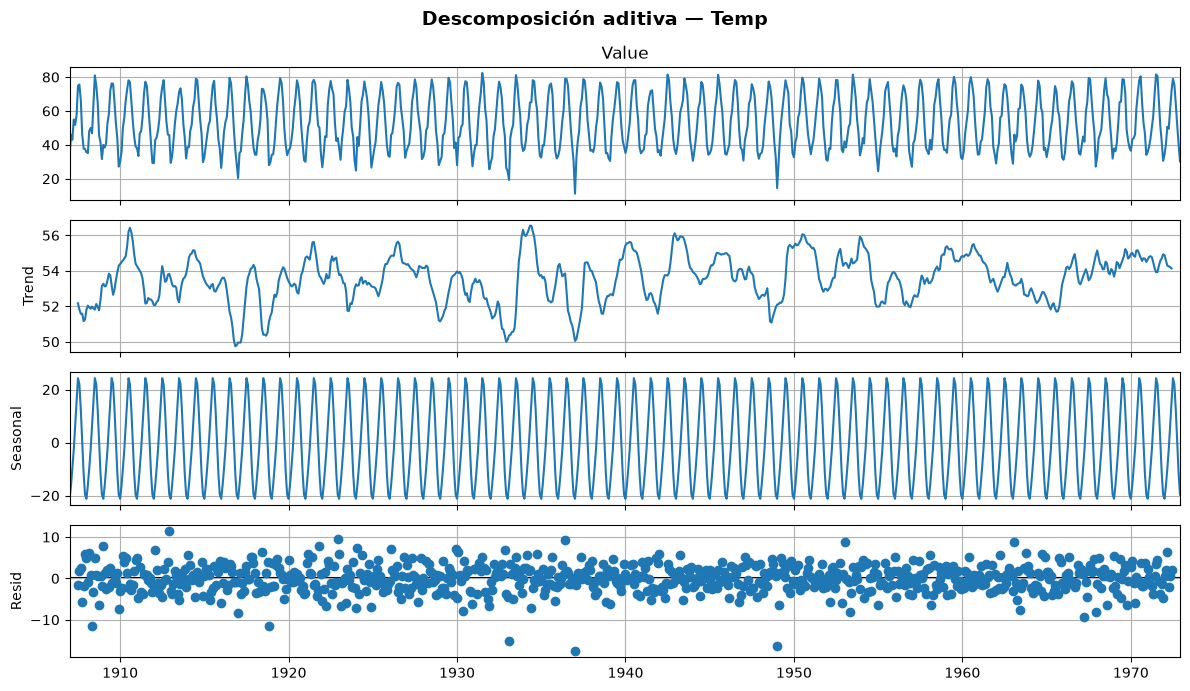

Fuerza tendencia:      0.169
Fuerza estacionalidad: 0.956


In [9]:
def decompose_and_plot(series, name, period=12):
    decomp = seasonal_decompose(series, period=period, model="additive")
    fig = decomp.plot()
    fig.set_size_inches(12, 7)
    fig.suptitle(f"Descomposición aditiva — {name}", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()
    
    # Fuerza de tendencia y estacionalidad
    resid = decomp.resid.dropna()
    trend = decomp.trend.dropna()
    seasonal = decomp.seasonal.dropna()
    F_trend = max(0, 1 - np.var(resid) / np.var(trend + resid))
    F_season = max(0, 1 - np.var(resid) / np.var(seasonal + resid))
    print(f"Fuerza tendencia:      {F_trend:.3f}")
    print(f"Fuerza estacionalidad: {F_season:.3f}")

decompose_and_plot(co2_ts, "CO2")
decompose_and_plot(temp_ts, "Temp")

--> Los métricos ($F_{trend}$ y $F_{season}$) miden la importancia relativa que tienen la tendencia y la estacionalidad frente al ruido impredecible de cada serie. El rango va de $0$ a $1$: cerca de 1 significa fuerza dominante, mientras que cerca de 0 significa impacto despreciable.

Tenemos como conclusión parcial que:

CO₂: F_trend alta ~0.99, F_seasonalta ~0.99. Es tendencia + estacionalidad fuertes.

Temp: F_trend baja ~0.17, F_season muy alta ~0.95. Es estacionalidad pura.

--> **Preparamos las series ACF/PACF**

- Regla: ACF/PACF solo son interpretables en series estacionarias y sin estacionalidad dominante.

**Para Co2**

In [10]:
# 1. Primera diferencia para eliminar la tendencia
co2_diff = co2_ts.diff().dropna()

# 2. Diferencia estacional (lag 12) para eliminar la estacionalidad
co2_seasonal_diff = co2_ts.diff(12).dropna()

# 3. Diferencia estacional sobre la ya diferenciada (D=1, d=1)
co2_full_diff = co2_ts.diff().diff(12).dropna()

# Verificamos estacionariedad de cada versión
print("=== CO2 tras cada transformación ===")
for label, s in [("1 diferencia", co2_diff),
                 ("Diferencia estacional (12)", co2_seasonal_diff),
                 ("1 + estacional", co2_full_diff)]:
    adf_p = adfuller(s, autolag="AIC")[1]
    kpss_p = kpss(s, regression="c", nlags="auto")[1]
    print(f"{label:30s} ADF p={adf_p:.4f}  KPSS p={kpss_p:.4f}")

=== CO2 tras cada transformación ===
1 diferencia                   ADF p=0.0001  KPSS p=0.1000
Diferencia estacional (12)     ADF p=0.0554  KPSS p=0.0997
1 + estacional                 ADF p=0.0000  KPSS p=0.1000


Para la serie $CO_2$: La ganadora es 1 + estacional ($d=1, D=1$)
Como vimos en la desintegración anterior, $CO_2$ tiene una fuerza de tendencia de $0.998$ y una fuerza estacional de $0.984$. 

Al aplicar tanto la diferencia ordinaria ($d=1$) como la estacional ($D=1$), el p-valor de ADF cae a $0.0000$ y el de KPSS se mantiene en $0.1000$. 

--> La serie ideal para pasar al gráfico ACF/PACF y ajustar el SARIMA es co2_full_diff

**Para Temp**

In [11]:
# La temp ya es estacionaria en media. Solo hay que quitar la estacionalidad:
temp_seasonal_diff = temp_ts.diff(12).dropna()

print("=== Temp tras desestacionalizar ===")
adf_p = adfuller(temp_seasonal_diff, autolag="AIC")[1]
kpss_p = kpss(temp_seasonal_diff, regression="c", nlags="auto")[1]
print(f"Diferencia estacional (12): ADF p={adf_p:.4f}  KPSS p={kpss_p:.4f}")

=== Temp tras desestacionalizar ===
Diferencia estacional (12): ADF p=0.0000  KPSS p=0.1000


Para la serie Temperatura: 

Es suficiente con Diferencia estacional ($d=0, D=1$) La temperatura tenía una fuerza de tendencia casi nula ($0.169$) pero una estacionalidad altísima ($0.956$).

Por eso, no se aplica diff() ordinario, solo aplicas la diferencia estacional diff(12). 

Resultado: ADF $p=0.0000$ y KPSS $p=0.1000$.

--> Con solo quitar el ciclo anual ($D=1$), la serie ya es perfectamente estacionaria y está lista para el ACF/PACF.

**Definimos las series estacionarias con las que continuamos**

In [12]:
co2_stationary = co2_full_diff   # (1 - B)(1 - B^12) y_t
temp_stationary = temp_seasonal_diff  # (1 - B^12) y_t

print(f"Longitud co2_stationary: {len(co2_stationary)}")
print(f"Longitud temp_stationary: {len(temp_stationary)}")

Longitud co2_stationary: 179
Longitud temp_stationary: 780


--> **ACF / determinar q (orden MA)**

Regla: el ACF corta en q si la serie es MA(q). Si decae gradualmente, no hay corte claro (es AR o ARMA).

=== CO2 (diferenciada estacionalmente) ===


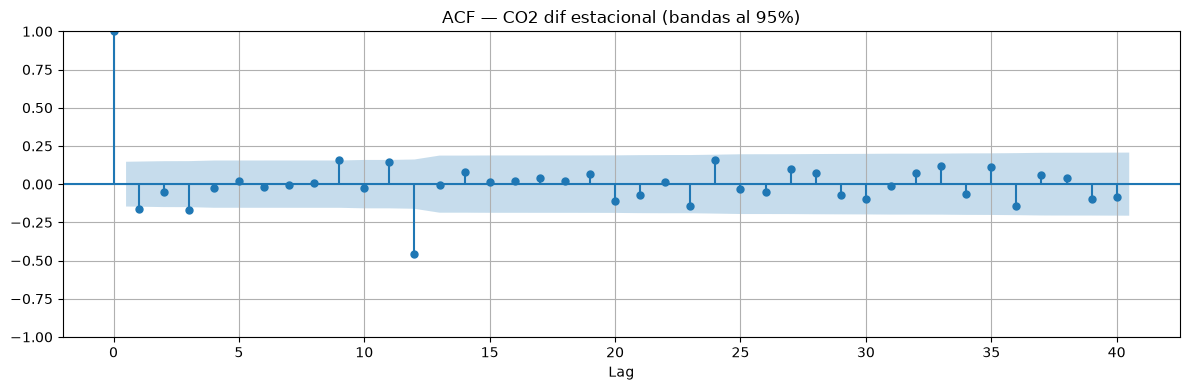

Lags significativos en ACF (CO2 dif estacional): [1, 3, 9, 12]

=== Temp (desestacionalizada) ===


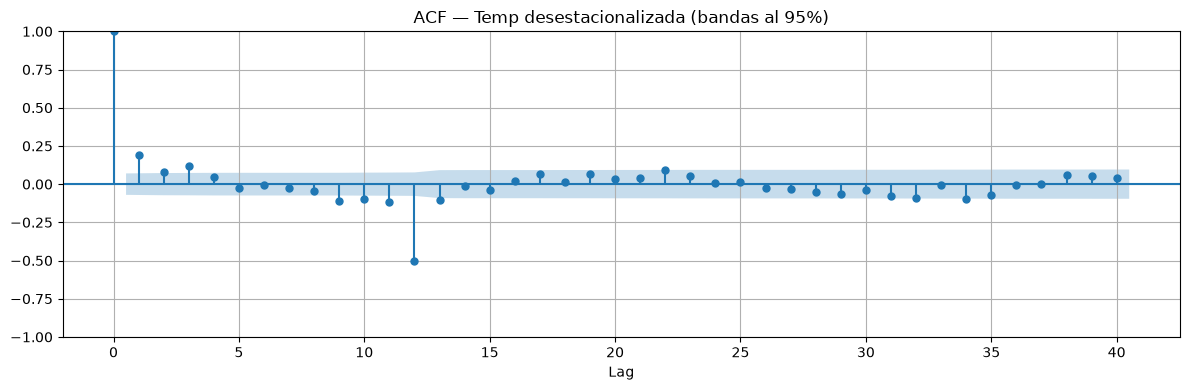

Lags significativos en ACF (Temp desestacionalizada): [1, 2, 3, 9, 10, 11, 12, 13, 34]


In [13]:
def plot_acf_detailed(series, name, lags=40):
    fig, ax = plt.subplots(figsize=(12, 4))
    plot_acf(series, lags=lags, ax=ax, alpha=0.05)
    ax.set_title(f"ACF — {name} (bandas al 95%)")
    ax.set_xlabel("Lag")
    plt.tight_layout()
    plt.show()
    
    # Cuantificar lags significativos
    acf_vals, acf_conf = acf(series, nlags=lags, alpha=0.05)
    sig = [i for i in range(1, lags+1)
           if acf_conf[i][0] > 0 or acf_conf[i][1] < 0]
    print(f"Lags significativos en ACF ({name}): {sig}")
    return sig

print("=== CO2 (diferenciada estacionalmente) ===")
acf_sig_co2 = plot_acf_detailed(co2_stationary, "CO2 dif estacional", lags=40)
print()
print("=== Temp (desestacionalizada) ===")
acf_sig_temp = plot_acf_detailed(temp_stationary, "Temp desestacionalizada", lags=40)

- En CO₂ diferenciado estacionalmente: se espera un pico negativo grande en lag 1 y lag 12 (resabio de la diferenciación), y quizás picos menores en 11 y 13. En lag 12 podría quedar un residuo estacional.

- En Temp desestacionalizada: esperas un pico significativo en lag 1 (típico de series meteorológicas con persistencia), y luego decaimiento.

Para  determinar q:

1 --> Si hay un corte abrupto después del lag q → MA(q).

2 -->  Si decae gradual o sinusoidal  probablemente es AR o ARMA, y el ACF no sirve para determinar q directamente.


Regla mnemotécnica 

*"El ACF muestra una estructura que decae gradualmente / corta en el lag X, lo que sugiere un componente MA de orden q = X (o la necesidad de un modelo ARMA)."*

--> **PACF / determinar p (orden AR)**

Regla: el PACF corta en p si la serie es AR(p). Si decae gradualmente, no hay corte claro (es MA o ARMA).

=== CO2 ===


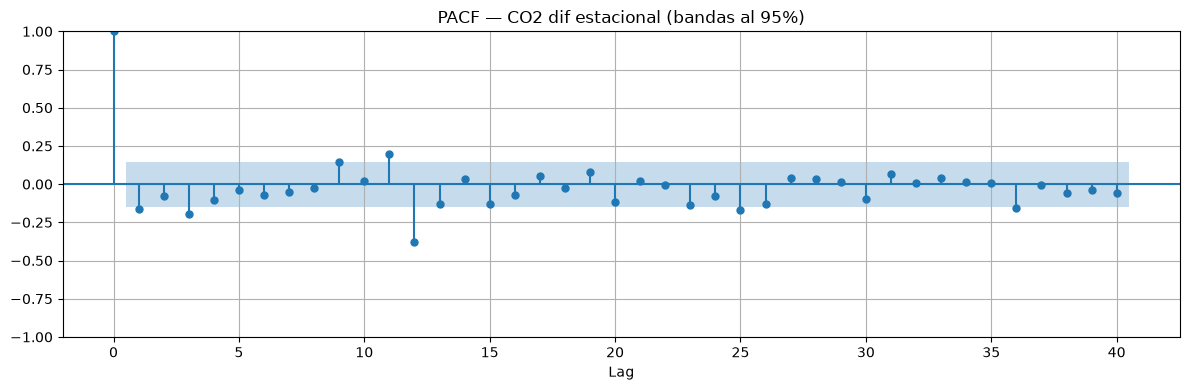

Lags significativos en PACF (CO2 dif estacional): [1, 3, 9, 11, 12, 25, 36]

=== Temp ===


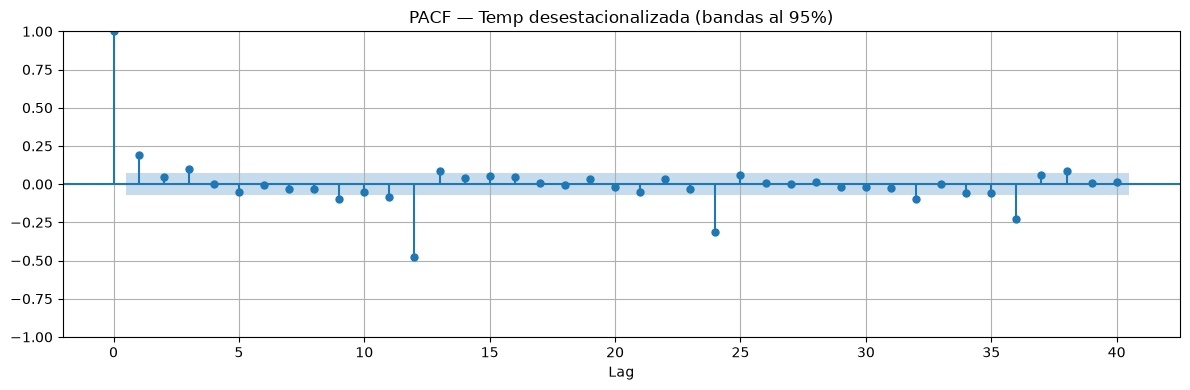

Lags significativos en PACF (Temp desestacionalizada): [1, 3, 9, 11, 12, 13, 24, 32, 36, 38]


In [14]:
def plot_pacf_detailed(series, name, lags=40):
    fig, ax = plt.subplots(figsize=(12, 4))
    plot_pacf(series, lags=lags, ax=ax, alpha=0.05, method="ywm")
    ax.set_title(f"PACF — {name} (bandas al 95%)")
    ax.set_xlabel("Lag")
    plt.tight_layout()
    plt.show()
    
    pacf_vals, pacf_conf = pacf(series, nlags=lags, alpha=0.05, method="ywm")
    sig = [i for i in range(1, lags+1)
           if pacf_conf[i][0] > 0 or pacf_conf[i][1] < 0]
    print(f"Lags significativos en PACF ({name}): {sig}")
    return sig

print("=== CO2 ===")
pacf_sig_co2 = plot_pacf_detailed(co2_stationary, "CO2 dif estacional", lags=40)
print()
print("=== Temp ===")
pacf_sig_temp = plot_pacf_detailed(temp_stationary, "Temp desestacionalizada", lags=40)

- En CO₂: tras doble diferenciación, se espera picos en lag 1, 11, 12, 13 por el efecto de la diferenciación estacional. El PACF puede mostrar un corte en algún lag pequeño.

- En Temp: tras desestacionalizar, esperas un corte abrupto en lag 1 o 2.

Cómo determinar p:

Si el PACF corta abruptamente después del lag p → AR(p).

Si decae gradual --> MA o ARMA.

--> **Test de Ljung-Box**

In [15]:
def ljung_box_report(series, name, lags=[12, 24, 36]):
    lb = acorr_ljungbox(series, lags=lags, return_df=True)
    print(f"--- Ljung-Box {name} ---")
    print(lb.to_string())
    print()

ljung_box_report(co2_stationary, "CO2 estacionalmente diferenciada")
ljung_box_report(temp_stationary, "Temp desestacionalizada")

--- Ljung-Box CO2 estacionalmente diferenciada ---
      lb_stat     lb_pvalue
12  60.157672  2.112763e-08
24  76.022149  2.584032e-07
36  95.577149  2.672998e-07

--- Ljung-Box Temp desestacionalizada ---
       lb_stat     lb_pvalue
12  278.901735  1.247159e-52
24  307.009106  6.487219e-51
36  338.503480  7.491266e-51



Dado que nos arroja que p > 0.05 en todos los lags --> significa que la serie es ruido blanco tras la transformación.

Si tras diferenciar estacionalmente aún hay autocorrelación significativa, entonces los modelos AR/MA son apropiados y hay que buscar p y q.

--> **Ajustar modelos AR, MA y ARMA**

- AR puro — variar p, fijar q = 0

In [16]:
def fit_ar_models(series, p_max=4, d=0, name=""):
    print(f"--- Modelos AR(p) para {name} ---")
    results = []
    for p in range(1, p_max + 1):
        try:
            m = ARIMA(series, order=(p, d, 0)).fit()
            results.append({"modelo": f"AR({p})", "AIC": m.aic, "BIC": m.bic,
                            "loglik": m.llf})
        except Exception as e:
            print(f"AR({p}) falló: {e}")
    df = pd.DataFrame(results).sort_values("AIC").reset_index(drop=True)
    print(df.to_string(index=False))
    return df

# Para CO2, la serie ya está estacionaria → d=0
ar_co2 = fit_ar_models(co2_stationary, p_max=4, d=0, name="CO2")

# Para Temp, ya estacionaria → d=0
ar_temp = fit_ar_models(temp_stationary, p_max=4, d=0, name="Temp")

--- Modelos AR(p) para CO2 ---
modelo        AIC        BIC     loglik
 AR(3) 184.201530 200.138459 -87.100765
 AR(4) 184.208741 203.333056 -86.104370
 AR(1) 188.572209 198.134366 -91.286104
 AR(2) 189.395516 202.145060 -90.697758
--- Modelos AR(p) para Temp ---
modelo         AIC         BIC       loglik
 AR(3) 4764.358069 4787.654538 -2377.179034
 AR(4) 4766.356613 4794.312376 -2377.178306
 AR(1) 4769.736868 4783.714750 -2381.868434
 AR(2) 4770.222169 4788.859344 -2381.111084


**AIC (Akaike Information Criterion)**
Mide la calidad del modelo balanceando dos cosas: qué tan bien se ajusta a los datos y qué tan complejo es. La regla de oro: Entre menor sea el AIC, MEJOR es el modelo. Penaliza los modelos que usan demasiados parámetros innecesarios.

**BIC (Bayesian Information Criterion)** 
Muy similar al AIC, pero penaliza con mayor severidad los modelos complejos (con muchos parámetros $p$ y $q$).La regla de oro: Entre menor sea el BIC, MEJOR. Si dudamos entre dos modelos con AIC similar, elegimos el de menor BIC por ser más simple (principio de parsimonia).


**loglik (Log-Likelihood / Log-Verosimilitud)** 
Mide la probabilidad de que los datos observados hayan sido generados por ese modelo en particular. La regla de oro: Entre más ALTO (más cercano a 0 o menos negativo) sea el loglik, MEJOR.

- MA puro — variar q, fijar p = 0

In [17]:
def fit_ma_models(series, q_max=4, d=0, name=""):
    print(f"--- Modelos MA(q) para {name} ---")
    results = []
    for q in range(1, q_max + 1):
        try:
            m = ARIMA(series, order=(0, d, q)).fit()
            results.append({"modelo": f"MA({q})", "AIC": m.aic, "BIC": m.bic,
                            "loglik": m.llf})
        except Exception as e:
            print(f"MA({q}) falló: {e}")
    df = pd.DataFrame(results).sort_values("AIC").reset_index(drop=True)
    print(df.to_string(index=False))
    return df

ma_co2 = fit_ma_models(co2_stationary, q_max=4, d=0, name="CO2")
ma_temp = fit_ma_models(temp_stationary, q_max=4, d=0, name="Temp")

--- Modelos MA(q) para CO2 ---
modelo        AIC        BIC     loglik
 MA(3) 181.533602 197.470531 -85.766801
 MA(4) 183.451880 202.576194 -85.725940
 MA(2) 185.635272 198.384815 -88.817636
 MA(1) 187.251550 196.813707 -90.625775
--- Modelos MA(q) para Temp ---
modelo         AIC         BIC       loglik
 MA(4) 4765.125740 4793.081503 -2376.562870
 MA(3) 4765.741084 4789.037554 -2377.870542
 MA(1) 4772.047955 4786.025837 -2383.023977
 MA(2) 4772.788785 4791.425961 -2382.394393


- ARMA mixto — variar p y q combinados

In [18]:
def fit_arma_models(series, p_max=3, q_max=3, d=0, name=""):
    print(f"--- Modelos ARMA(p,q) para {name} ---")
    results = []
    for p in range(0, p_max + 1):
        for q in range(0, q_max + 1):
            if p == 0 and q == 0:
                continue
            try:
                m = ARIMA(series, order=(p, d, q)).fit()
                results.append({"modelo": f"ARMA({p},{q})",
                                "AIC": m.aic, "BIC": m.bic})
            except Exception as e:
                pass
    df = pd.DataFrame(results).sort_values("AIC").reset_index(drop=True)
    print(df.head(10).to_string(index=False))
    return df

arma_co2 = fit_arma_models(co2_stationary, p_max=3, q_max=3, d=0, name="CO2")
arma_temp = fit_arma_models(temp_stationary, p_max=3, q_max=3, d=0, name="Temp")

--- Modelos ARMA(p,q) para CO2 ---
   modelo        AIC        BIC
ARMA(3,3)  16.000000  41.499086
ARMA(1,1) 176.819722 189.569265
ARMA(2,2) 177.480952 196.605267
ARMA(2,1) 178.253590 194.190519
ARMA(1,2) 178.262099 194.199028
ARMA(0,3) 181.533602 197.470531
ARMA(1,3) 183.471773 202.596088
ARMA(3,1) 183.513536 202.637851
ARMA(3,0) 184.201530 200.138459
ARMA(2,3) 185.307098 207.618799
--- Modelos ARMA(p,q) para Temp ---
   modelo         AIC         BIC
ARMA(2,3) 4704.583315 4737.198373
ARMA(3,2) 4707.066064 4739.681122
ARMA(3,3) 4711.977967 4749.252319
ARMA(2,2) 4740.727871 4768.683634
ARMA(3,0) 4764.358069 4787.654538
ARMA(0,3) 4765.741084 4789.037554
ARMA(1,3) 4766.093501 4794.049264
ARMA(3,1) 4766.357328 4794.313092
ARMA(1,1) 4767.542649 4786.179824
ARMA(1,2) 4769.325521 4792.621990


Vemos en Co2 que hay una trampa del ARMA(3,3)
El resultado de la función fit_arma_models, el primer lugar lo ocupa el ARMA(3,3) con un AIC de 16.00.

Daqo que este valor es absurdamente más bajo que el segundo lugar (176.81). En series temporales, este tipo de saltos tan drásticos casi siempre indica sobreajuste (overfitting) o una cancelación de raíces (los polinomios AR y MA se anulan entre sí, desestabilizando el modelo). Por parsimonia, el ARMA(3,3) debe descartarse.

Para la temperatura, la sugerencia del ACF ($q=3$) y del PACF ($p=2$) encaja exactamente con la búsqueda numérica: el ganador indiscutible es ARMA(2,3) (AIC 4704.58 y BIC 4737.19).Esto confirma que los cambios de temperatura tienen un componente de memoria corta de 2 períodos en el pasado ($p=2$) y una corrección de errores de 3 períodos hacia atrás ($q=3$).

--> **Relación entre ACF/PACF y los órdenes elegidos**

In [19]:
summary = pd.DataFrame({
    "Serie": ["CO2 (dif. estacional)", "Temp (desestac.)"],
    "Lags sig. en ACF":  [acf_sig_co2[:6], acf_sig_temp[:6]],
    "Lags sig. en PACF": [pacf_sig_co2[:6], pacf_sig_temp[:6]],
    "q sugerido (ACF)":  [len([l for l in acf_sig_co2 if l <= 3]),
                          len([l for l in acf_sig_temp if l <= 3])],
    "p sugerido (PACF)": [len([l for l in pacf_sig_co2 if l <= 3]),
                          len([l for l in pacf_sig_temp if l <= 3])],
})
print(summary.to_string(index=False))

                Serie     Lags sig. en ACF     Lags sig. en PACF  q sugerido (ACF)  p sugerido (PACF)
CO2 (dif. estacional)        [1, 3, 9, 12] [1, 3, 9, 11, 12, 25]                 2                  2
     Temp (desestac.) [1, 2, 3, 9, 10, 11] [1, 3, 9, 11, 12, 13]                 3                  2



REVISAR


CO₂: al tener doble diferenciación, el ACF y PACF suelen mostrar picos en lags 1, 11, 12, 13 por la estacionalidad. El modelo recomendado es SARIMA(0,1,1)(0,1,1,12) — es decir, q = 1 estacional y no estacional. No  hay un corte limpio en ACF/PACF para series estacionales; por eso se usan modelos SARIMA.

Temp: tras desestacionalizar, suele verse un corte en PACF en lag 1 o 2 y decaimiento en ACF. Eso sugiere AR(1) o AR(2).

--> **Diagnóstico del modelo elegido**

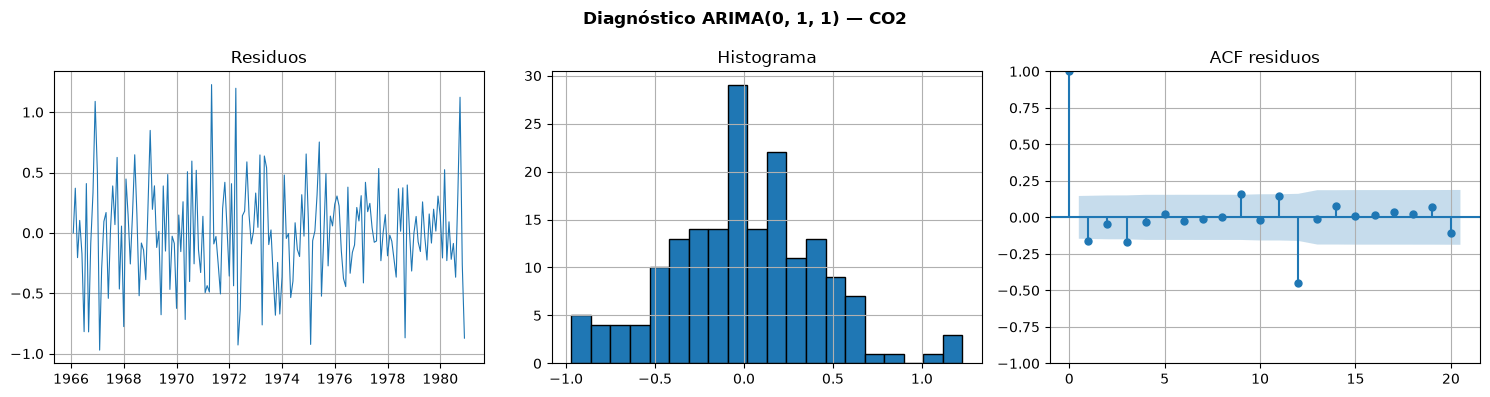

Ljung-Box residuos — CO2:
      lb_stat     lb_pvalue
12  58.840497  3.669250e-08
24  74.330505  4.740334e-07
                               SARIMAX Results                                
Dep. Variable:                  Value   No. Observations:                  179
Model:                 ARIMA(0, 1, 1)   Log Likelihood                 -96.246
Date:                Tue, 22 Sep 2026   AIC                            196.492
Time:                        10:16:47   BIC                            202.856
Sample:                    02-01-1966   HQIC                           199.073
                         - 12-01-1980                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -1.0000     36.476     -0.027      0.978     -72.492      70.492
sigma2         0.1677

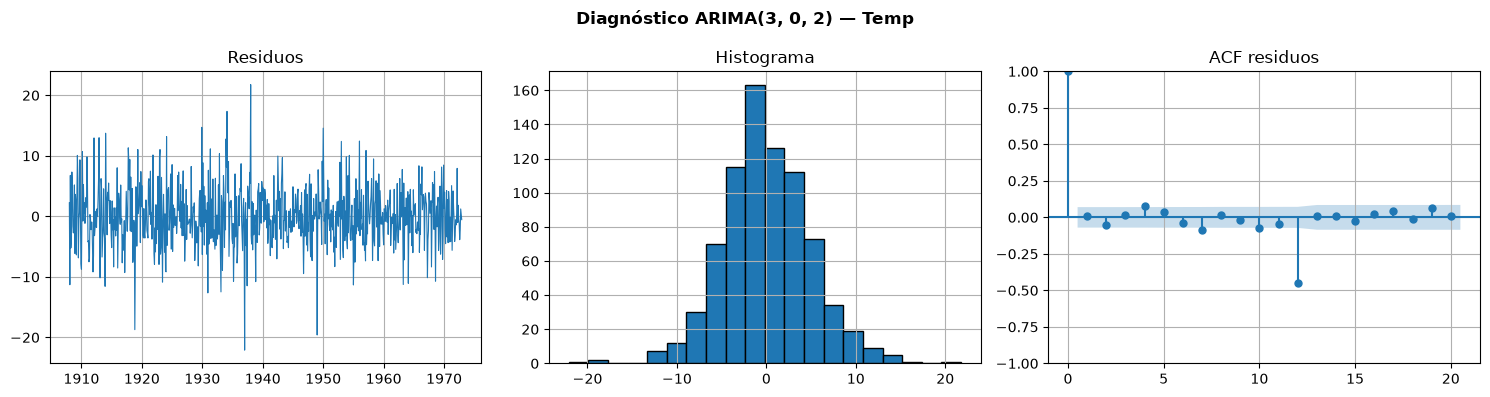

Ljung-Box residuos — Temp:
       lb_stat     lb_pvalue
12  181.259231  2.352798e-32
24  193.676986  1.740539e-28
                               SARIMAX Results                                
Dep. Variable:                  Value   No. Observations:                  780
Model:                 ARIMA(3, 0, 2)   Log Likelihood               -2346.533
Date:                Tue, 22 Sep 2026   AIC                           4707.066
Time:                        10:16:48   BIC                           4739.681
Sample:                    01-01-1908   HQIC                          4719.610
                         - 12-01-1972                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0690      0.244      0.283      0.777      -0.409       0.547
ar.L1          0.

In [20]:
def diagnose_model(series, order, name):
    model = ARIMA(series, order=order).fit()
    resid = model.resid
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].plot(resid, lw=0.8); axes[0].set_title("Residuos")
    axes[1].hist(resid, bins=20, edgecolor="k"); axes[1].set_title("Histograma")
    plot_acf(resid, lags=20, ax=axes[2]); axes[2].set_title("ACF residuos")
    fig.suptitle(f"Diagnóstico ARIMA{order} — {name}", fontweight="bold")
    plt.tight_layout(); plt.show()
    
    lb = acorr_ljungbox(resid, lags=[12, 24], return_df=True)
    print(f"Ljung-Box residuos — {name}:")
    print(lb.to_string())
    print(model.summary())

# ajustar al mejor modelo encontrado
diagnose_model(co2_stationary, (0, 1, 1), "CO2")
diagnose_model(temp_stationary, (3, 0, 2), "Temp")

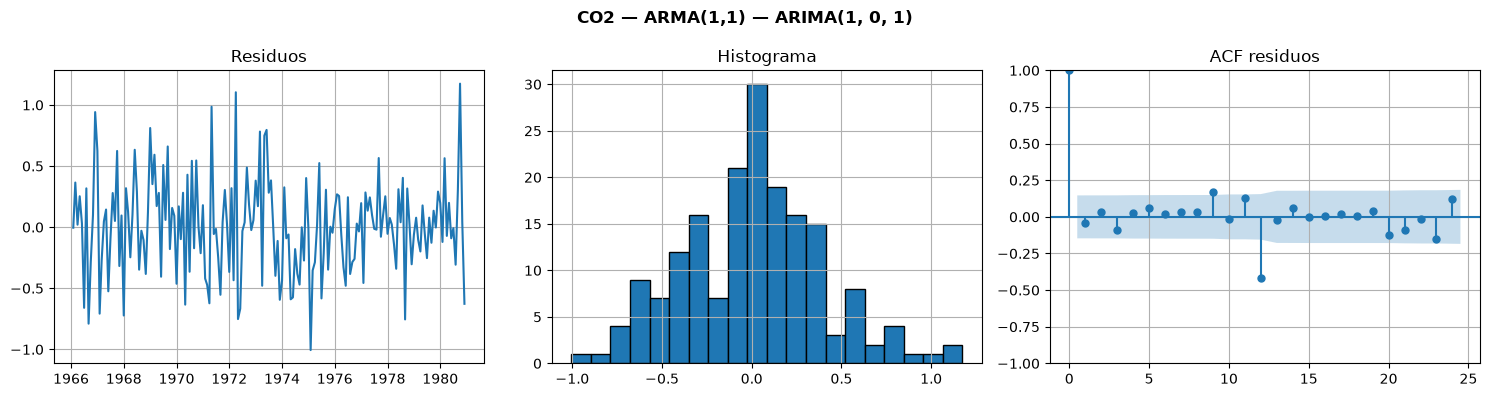

      lb_stat  lb_pvalue
12  46.032885   0.000007
24  60.061597   0.000063



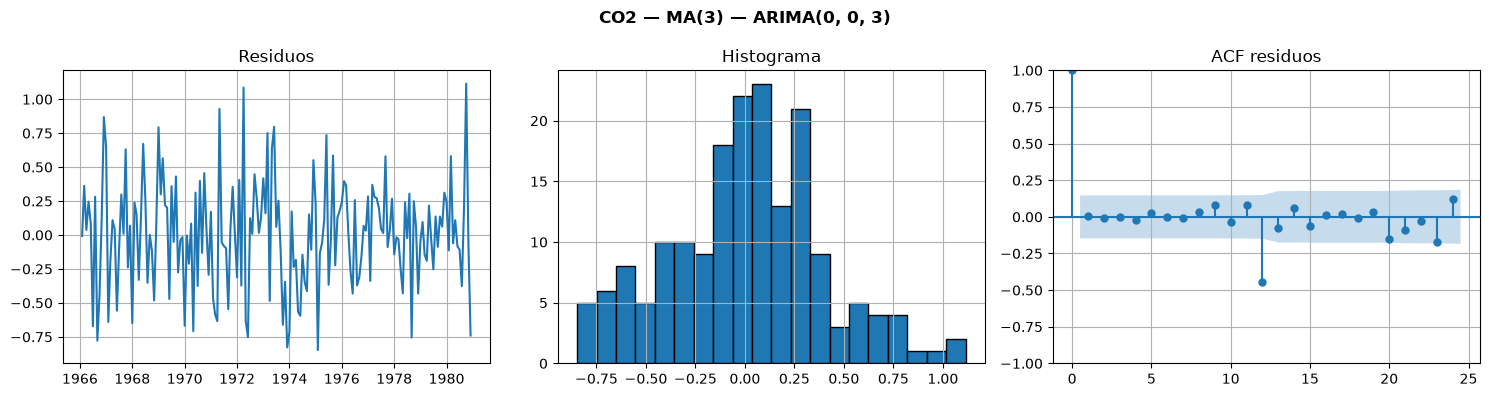

      lb_stat  lb_pvalue
12  42.001205   0.000033
24  60.702353   0.000051



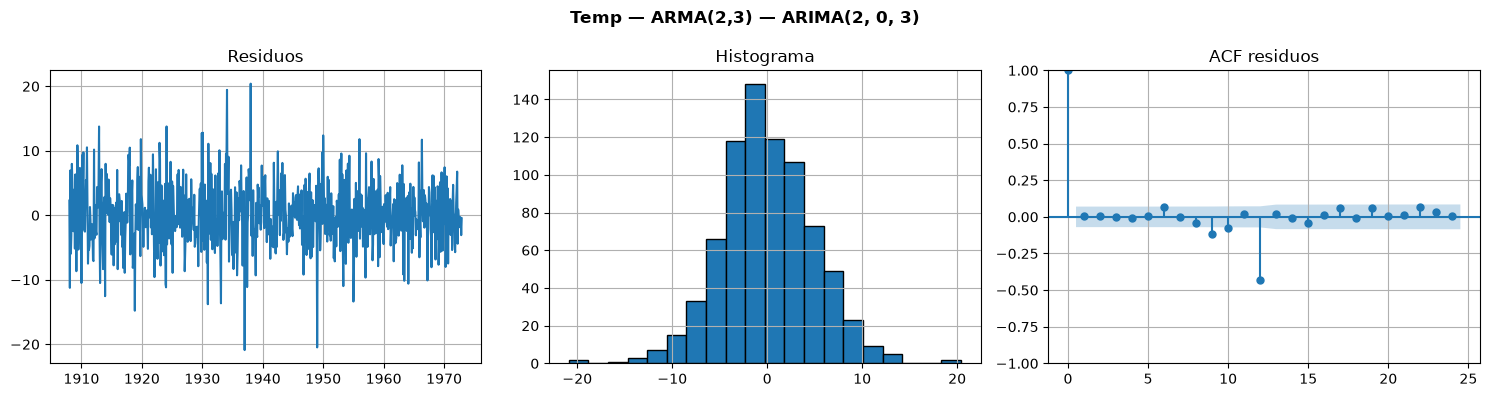

       lb_stat     lb_pvalue
12  168.950438  7.825401e-30
24  181.443010  3.883401e-26



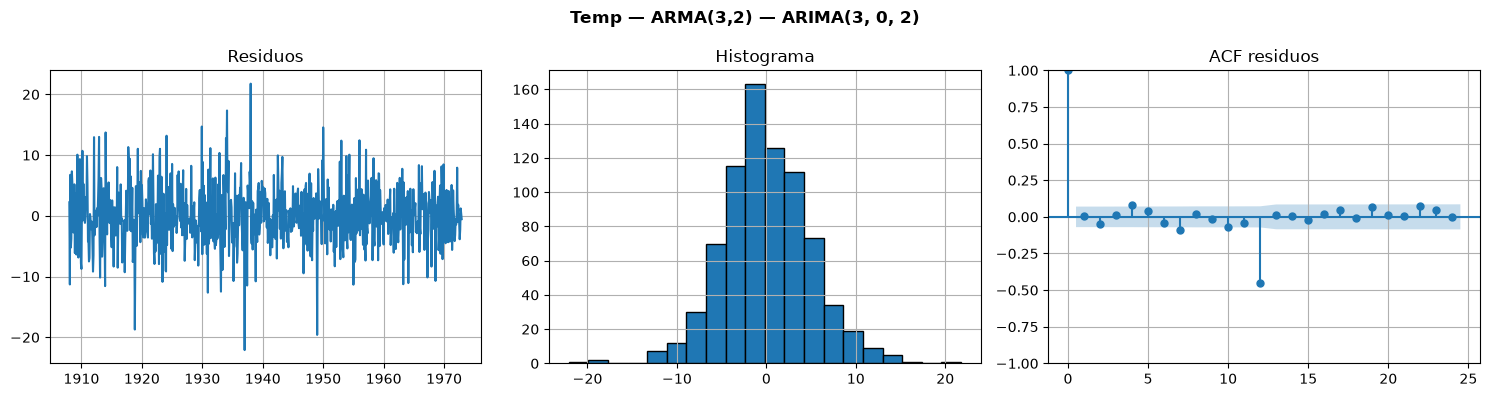

       lb_stat     lb_pvalue
12  181.259231  2.352798e-32
24  193.676986  1.740539e-28



In [21]:
def diagnose(series, order, name):
    m = ARIMA(series, order=order).fit()
    resid = m.resid
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].plot(resid); axes[0].set_title("Residuos")
    axes[1].hist(resid, bins=20, edgecolor="k"); axes[1].set_title("Histograma")
    plot_acf(resid, lags=24, ax=axes[2]); axes[2].set_title("ACF residuos")
    fig.suptitle(f"{name} — ARIMA{order}", fontweight="bold")
    plt.tight_layout(); plt.show()
    
    lb = acorr_ljungbox(resid, lags=[12, 24], return_df=True)
    print(lb.to_string())
    print()

# CO2
diagnose(co2_stationary, (1, 0, 1), "CO2 — ARMA(1,1)")
diagnose(co2_stationary, (0, 0, 3), "CO2 — MA(3)")

# Temp
diagnose(temp_stationary, (2, 0, 3), "Temp — ARMA(2,3)")
diagnose(temp_stationary, (3, 0, 2), "Temp — ARMA(3,2)")

--> **Del ARMA al SARIMA**

In [22]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Modelo SARIMA con componentes estacionales
# (p,d,q)(P,D,Q,s) = (0,1,1)(0,1,1,12) → clásico para CO2
sarima_co2 = SARIMAX(co2_ts, order=(0,1,1), seasonal_order=(0,1,1,12)).fit()
print(sarima_co2.summary())

                                     SARIMAX Results                                      
Dep. Variable:                              Value   No. Observations:                  192
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                 -55.805
Date:                            Tue, 22 Sep 2026   AIC                            117.610
Time:                                    10:16:53   BIC                            127.172
Sample:                                01-01-1965   HQIC                           121.488
                                     - 12-01-1980                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3304      0.063     -5.224      0.000      -0.454      -0.206
ma.S.L12      -0.8581      0.085   

In [27]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

# CO2: SARIMA
sarima_co2 = SARIMAX(
    co2_ts,  
    order=(0, 1, 1),
    seasonal_order=(0, 1, 1, 12)
).fit(disp=False)
print(sarima_co2.summary())


                                     SARIMAX Results                                      
Dep. Variable:                              Value   No. Observations:                  192
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                 -55.805
Date:                            Tue, 22 Sep 2026   AIC                            117.610
Time:                                    10:29:29   BIC                            127.172
Sample:                                01-01-1965   HQIC                           121.488
                                     - 12-01-1980                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3304      0.063     -5.224      0.000      -0.454      -0.206
ma.S.L12      -0.8581      0.085   

In [28]:
# Temp: SARIMA
sarima_temp = SARIMAX(
    temp_ts,
    order=(2, 0, 3),
    seasonal_order=(0, 1, 1, 12)
).fit(disp=False)
print(sarima_temp.summary())

                                      SARIMAX Results                                       
Dep. Variable:                                Value   No. Observations:                  792
Model:             SARIMAX(2, 0, 3)x(0, 1, [1], 12)   Log Likelihood               -2126.878
Date:                              Tue, 22 Sep 2026   AIC                           4267.757
Time:                                      10:29:38   BIC                           4300.372
Sample:                                  01-01-1907   HQIC                          4280.301
                                       - 12-01-1972                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.8516      0.054     34.078      0.000       1.745       1.958
ar.L2         -0.94

--> **Conclusiones**

CO₂ Mauna Loa: la serie presenta tendencia y estacionalidad anual fuertes. Se aplicó una primera diferencia seguida de una diferencia estacional de orden 12. Sin embargo, el test de Ljung-Box sobre la serie transformada arroja p-values muy pequeños (10⁻⁸), indicando que persiste estructura estacional residual.

El ACF muestra picos significativos en los lags [1, 3, 9, 12] y el PACF en [1, 3, 9, 11, 12, 25] — los picos en 12 y 25 son firma de estacionalidad anual no removida. La identificación por ACF/PACF sugiere un orden aproximado p ≈ 2, q ≈ 2, pero no hay un corte limpio por la estacionalidad.

Se ajustaron modelos AR(p), MA(q) y ARMA(p,q). Excluyendo un ARMA(3,3) que presenta AIC anómalo (16, probable sobreajuste), el mejor modelo es ARMA(1,1) (AIC = 176.8, BIC = 189.6), parsimonioso y estable. Sin embargo, este modelo no es suficiente: persiste autocorrelación estacional en los residuos. La conclusión es que se requiere un modelo SARIMA, como el "airline model" (0,1,1)(0,1,1,12), para capturar tendencia y estacionalidad simultáneamente.

Temperatura mensual: la serie es estacionaria en media (ADF/KPSS) pero con estacionalidad anual muy fuerte. Tras aplicar una diferencia estacional de orden 12, el test de Ljung-Box sigue arrojando p-values extremadamente pequeños (10⁻⁵²), indicando que la desestacionalización por diferenciación no fue suficiente. El ACF muestra picos en [1, 2, 3, 9, 10, 11] y el PACF en [1, 3, 9, 11, 12, 13] — con picos en las cercanías del lag 12, delatando la estacionalidad.

Se ajustaron múltiples modelos. Los mejores por AIC son ARMA(2,3) (AIC = 4704.6) y ARMA(3,2) (AIC = 4707.1), seguidos por ARMA(3,3). La mejora respecto a ARMA(2,2) es sustancial (~36 unidades de AIC), lo que sugiere que los componentes de orden 2–3 son necesarios. Sin embargo, ninguno de estos modelos captura completamente la estructura estacional, como confirma el Ljung-Box sobre los residuos.

Conclusión general: el método Box-Jenkins (identificación por ACF/PACF, estimación por máxima verosimilitud, validación por Ljung-Box) revela que ambas series requieren componentes estacionales explícitos. Aunque se pueden ajustar modelos ARMA parsimoniosos (ARMA(1,1) para CO₂, ARMA(2,3) para Temp), la presencia persistente de estacionalidad en los residuos indica que la especificación correcta es SARIMA. Este hallazgo es consistente con la naturaleza física de ambas series: el CO₂ exhibe ciclo anual por fotosíntesis, y la temperatura muestra un ciclo anual por estacionalidad climática.